# A/B: xám vs RGB, cùng penalty thấp
Mục đích: tách riêng ảnh hưởng của đầu vào RGB, không lẫn với penalty cao.
Cả hai run dùng cùng seed, cùng cấu hình, chỉ khác `rgb_scale`. Penalty theo mốc ban đầu trong `Reports/update_death_penalty.md`: `death_penalty=2.5`, không step penalty.

In [1]:
from pacman_rl import PPOConfig, train_ppo, get_device
from pacman_rl.runs import save_run

device = get_device()
STEPS = 3_000_000

def make_cfg(rgb_scale):
    return PPOConfig(
        total_steps=STEPS,
        lr=2.5e-4,
        seed=0,
        save_every=50_000,
        death_penalty=2.5,
        n_envs=32,
        n_steps=512,
        n_minibatches=4,
        rgb_scale=rgb_scale,
    )

## A. Xám

In [ ]:
name_a = "ab_gray_dp25"

result_a = train_ppo(cfg=make_cfg(False), model=None, save_path=f"runs/{name_a}.pt", device=device)
save_run(result_a, "runs", name_a, append=False)

PPO: 183 updates x 16384 mẫu = 2,998,272 bước, 32 env song song
Update 50/183 | step 819,200 | avg score(20) 610 | 3911 lượt | 209 bước/lượt | 0.28 viên NL/lượt | 0.19 ma/lượt | entropy 1.785 | KL 0.0052 | clipfrac 0.266 | 1241 steps/s
Update 100/183 | step 1,638,400 | avg score(20) 790 | 3755 lượt | 218 bước/lượt | 0.35 viên NL/lượt | 0.23 ma/lượt | entropy 1.635 | KL 0.0006 | clipfrac 0.009 | 1323 steps/s
Update 150/183 | step 2,457,600 | avg score(20) 860 | 3791 lượt | 216 bước/lượt | 0.35 viên NL/lượt | 0.21 ma/lượt | entropy 1.736 | KL 0.0003 | clipfrac 0.000 | 1492 steps/s
Update 183/183 | step 2,998,272 | avg score(20) 674 | 2505 lượt | 216 bước/lượt | 0.35 viên NL/lượt | 0.22 ma/lượt | entropy 1.725 | KL -0.0000 | clipfrac 0.000 | 1497 steps/s


(WindowsPath('runs/ab_gray_dp25.pt'),
 WindowsPath('runs/ab_gray_dp25_episodes.npy'),
 WindowsPath('runs/ab_gray_dp25_log.npy'))

## B. RGB

In [3]:
name_b = "ab_rgb_dp25"
result_b = train_ppo(cfg=make_cfg(True), model=None, save_path=f"runs/{name_b}.pt", device=device)
save_run(result_b, "runs", name_b, append=False)

PPO: 183 updates x 16384 mẫu = 2,998,272 bước, 32 env song song
Update 50/183 | step 819,200 | avg score(20) 741 | 3945 lượt | 208 bước/lượt | 0.25 viên NL/lượt | 0.17 ma/lượt | entropy 1.879 | KL 0.0000 | clipfrac 0.000 | 1782 steps/s
Update 100/183 | step 1,638,400 | avg score(20) 826 | 3737 lượt | 219 bước/lượt | 0.36 viên NL/lượt | 0.23 ma/lượt | entropy 1.728 | KL 0.0004 | clipfrac 0.000 | 2092 steps/s
Update 150/183 | step 2,457,600 | avg score(20) 662 | 3799 lượt | 216 bước/lượt | 0.35 viên NL/lượt | 0.22 ma/lượt | entropy 1.695 | KL 0.0002 | clipfrac 0.005 | 2219 steps/s
Update 183/183 | step 2,998,272 | avg score(20) 772 | 2550 lượt | 212 bước/lượt | 0.33 viên NL/lượt | 0.20 ma/lượt | entropy 1.644 | KL 0.0001 | clipfrac 0.000 | 2256 steps/s


(WindowsPath('runs/ab_rgb_dp25.pt'),
 WindowsPath('runs/ab_rgb_dp25_episodes.npy'),
 WindowsPath('runs/ab_rgb_dp25_log.npy'))

## So sánh
Cần nhìn: điểm trung bình, entropy (xuống nhanh hay chậm), số bước mỗi mạng, số viên năng lượng và ma mỗi mạng.
- B ngang hoặc hơn A: RGB không phải thủ phạm, penalty cao mới là vấn đề.
- B kém rõ rệt so với A: RGB (hoặc kích thước đầu vào lớn gấp 3) làm chậm học, cần train lâu hơn hoặc đổi kiến trúc.

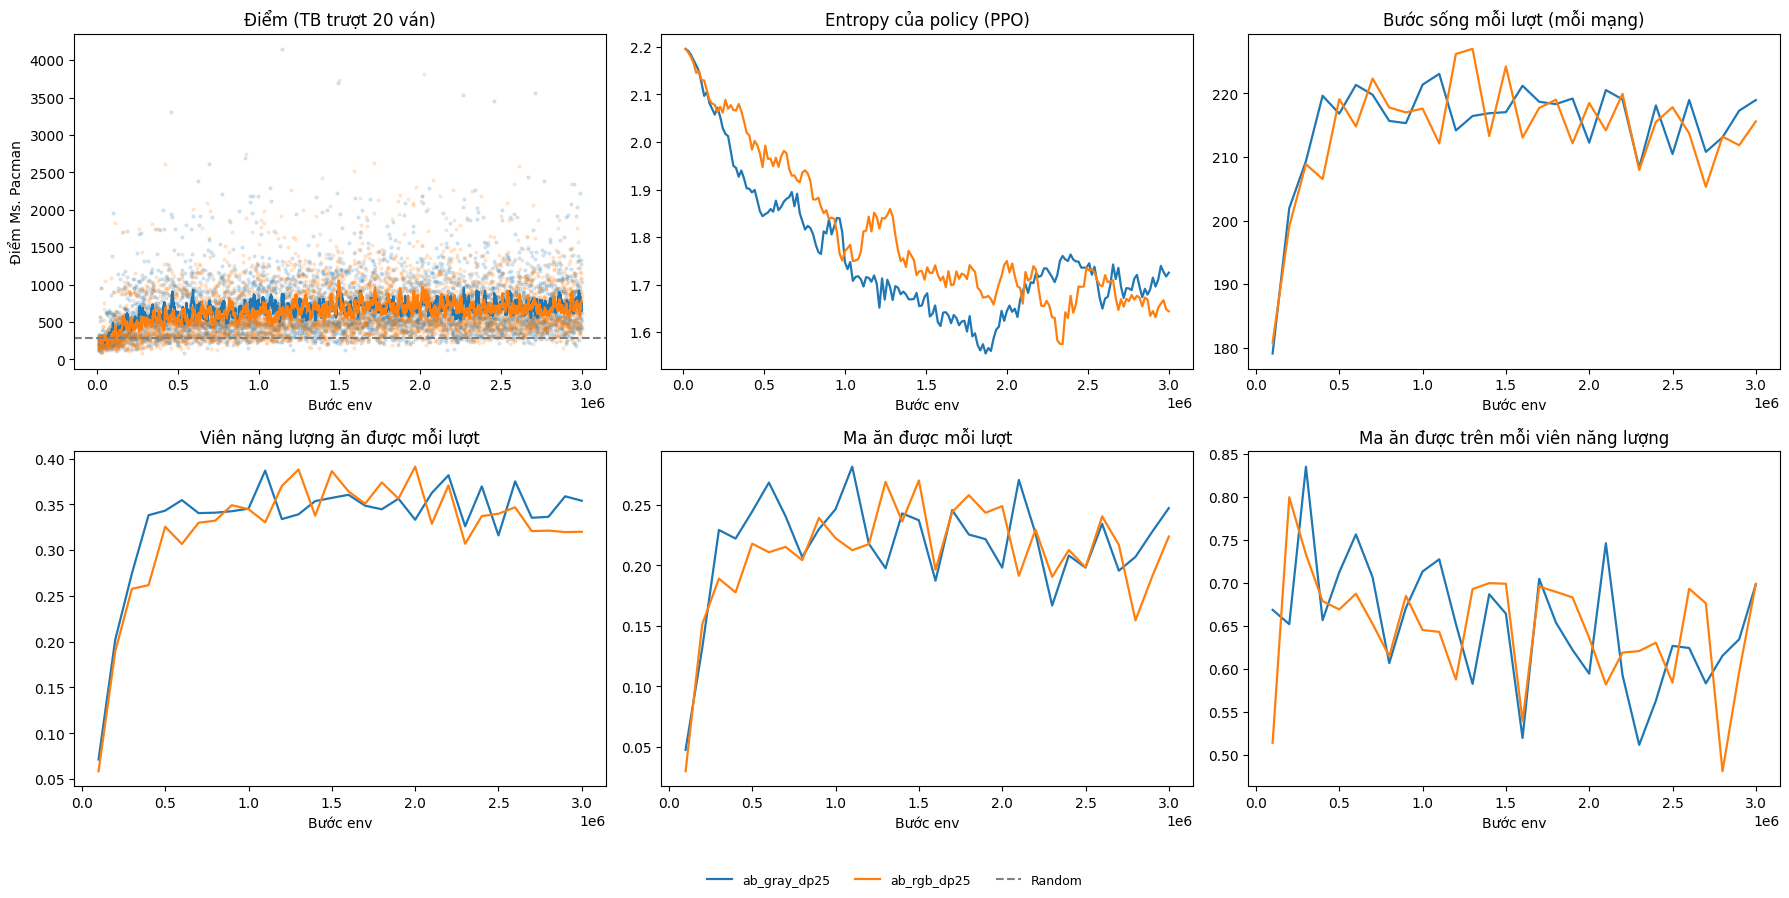

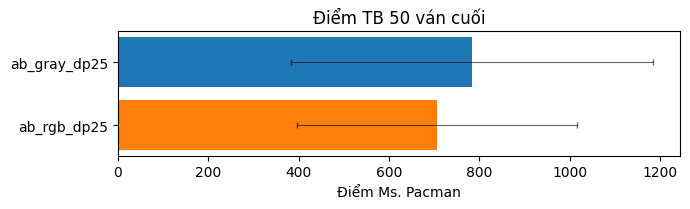

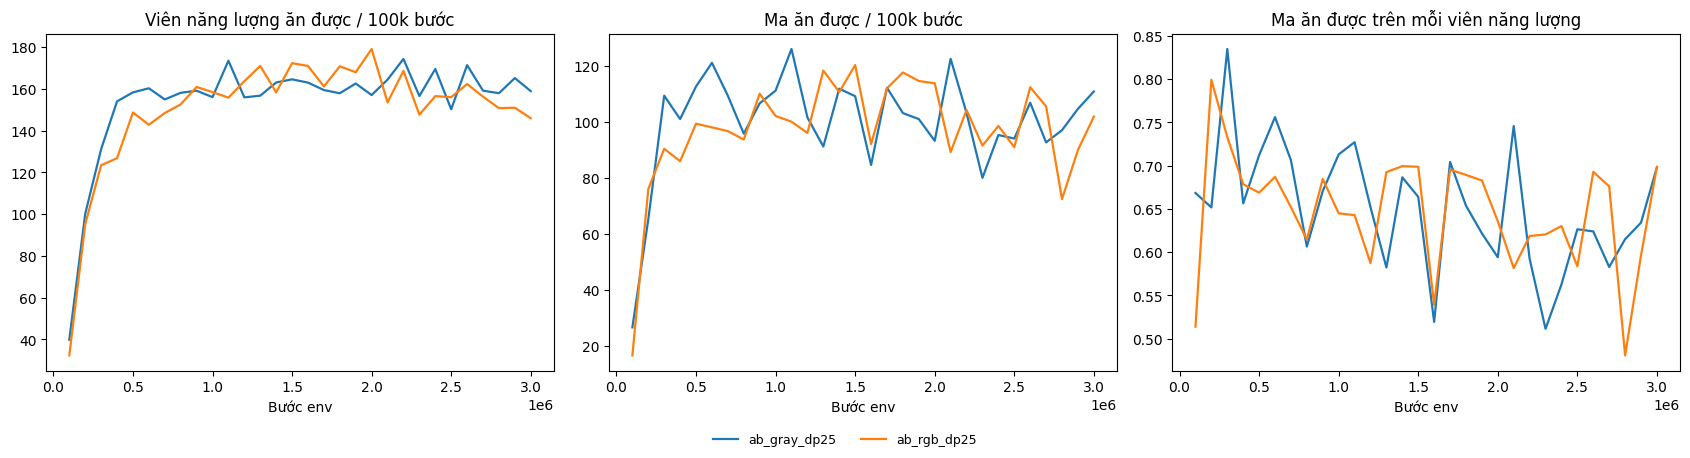

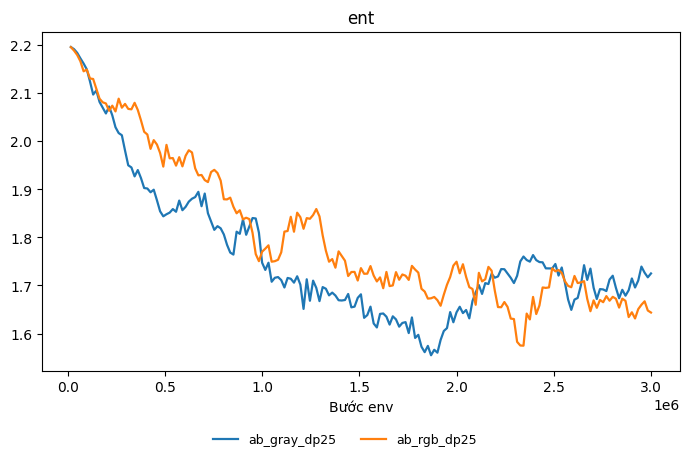

In [4]:
from pacman_rl.plotting import compare
from pacman_rl import random_baseline

runs = compare(["ab_gray_dp25", "ab_rgb_dp25"], directory="runs",
               random_scores=random_baseline(5), metrics=("ent",), device=device,
               save_path="runs/ab_gray_vs_rgb.png")